

## Customer Churn Prediction — Multi-Algorithm Classification Showdown

# 🧠 Step 1: Problem Framing & Theory Notes

#### 1. What is Customer Churn? Why is predicting churn valuable for a business like Jio or Airtel? (Mention CAC vs CLV in your answer.)

**Answer:**
- Churn means a paying customer leaves the service (stops the subscription).
- Getting a new customer (CAC - Customer Acquisition Cost) is much more expensive than keeping an old one.
- Every churned customer also takes away his future revenue (CLV - Customer Lifetime Value).
- If Jio/Airtel can predict who will leave, the retention team can give offers in time and protect the revenue.

#### 2. Define the four cells of a Confusion Matrix (TP, TN, FP, FN). In the churn context — what is the business cost of a False Negative? What about a False Positive?

**Answer:**
- **TP:** customer actually churned and model predicted churn. **TN:** customer actually stayed and model predicted stay.
- **FP:** customer actually stayed but model predicted churn. **FN:** customer actually churned but model predicted stay.
- Cost of FN is high: we lose the customer and his CLV, and we never tried to save him.
- Cost of FP is low: we only waste a small offer or a call on a customer who would stay anyway.

#### 3. What is Class Imbalance? Does the Telco Churn dataset have it? How does SMOTE address it?

**Answer:**
- Class imbalance means one class has far less data than the other class, so the model becomes biased to the majority class.
- Yes, Telco data is imbalanced - about 26.5% customers churned and 73.5% stayed (confirmed in Step 2).
- SMOTE creates new synthetic samples of the minority class using its nearest neighbours, so both classes become equal in training data.

#### 4. Briefly explain how each of the 4 algorithms you will use works — KNN, Naive Bayes, SVM, Decision Tree (2–3 lines each).

**Answer:**
- **KNN:** it stores all the training data. For a new customer it finds the k nearest customers and takes the majority class among them.
- **Naive Bayes:** it uses Bayes theorem to find the probability of each class given the features, and it assumes all features are independent.
- **SVM:** it finds the best boundary (hyperplane) with the maximum margin between the two classes. With the RBF kernel it can make a non-linear boundary.
- **Decision Tree:** it keeps splitting the data with yes/no questions on features (like Contract = Month-to-month?) and each leaf gives the final class.

#### 5. When would you choose Precision over Recall as your primary metric? Give a churn-specific answer.

**Answer:**
- Precision is more important when the retention action is costly or the calling capacity is limited.
- Example: if the team can call only ~500 customers a day or gives a big discount, wrongly flagged loyal customers waste money and call slots.

# 📂 Step 2: Dataset Loading & Exploratory Data Analysis

## 2.1 Load & Inspect

#### Load WA_Fn-UseC_-Telco-Customer-Churn.csv using pandas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

#### Print .shape, .info(), .describe(), and .head(10).

In [2]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [3]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


####  The TotalCharges column loads as object — convert it to float64. Investigate why (hint: whitespace rows) and handle them.

In [5]:
# investigating why it is object: rows having only a blank space
blank = df[df['TotalCharges'].str.strip() == '']
print(len(blank))
blank[['tenure', 'MonthlyCharges', 'TotalCharges']]

11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [6]:
# convert to float64 (blank space becomes NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

float64
11


**Answer:**
These 11 rows have a blank space in TotalCharges, so pandas read the column as object. All of them have tenure = 0, which means they are new customers who are not billed yet. They are converted to NaN and filled with the median in Step 3.1.

#### Check and report class balance: What % of customers churned? Is this imbalanced?

In [7]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Answer:**
26.5% customers churned (1869) and 73.5% stayed (5174). Yes, the data is imbalanced (roughly 3 : 1).

## 2.2 Univariate Analysis

#### Plot a countplot of the target variable Churn.

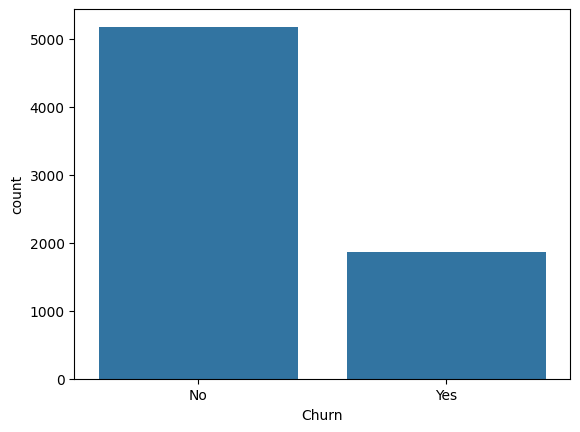

In [8]:
sns.countplot(x='Churn', data=df)
plt.show()

#### Plot histograms for: tenure, MonthlyCharges, TotalCharges.

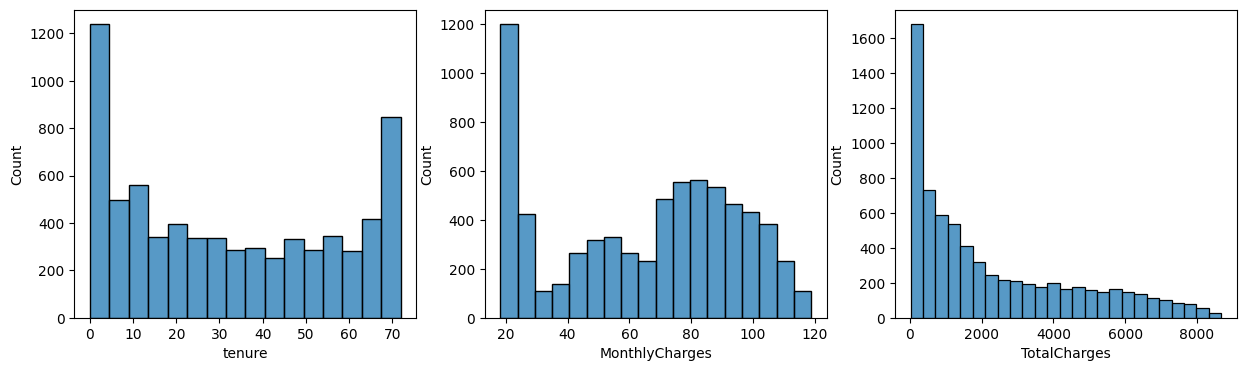

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['tenure'], ax=ax[0])
sns.histplot(df['MonthlyCharges'], ax=ax[1])
sns.histplot(df['TotalCharges'], ax=ax[2])
plt.show()

#### Plot countplots for key categorical features: Contract, InternetService, PaymentMethod.

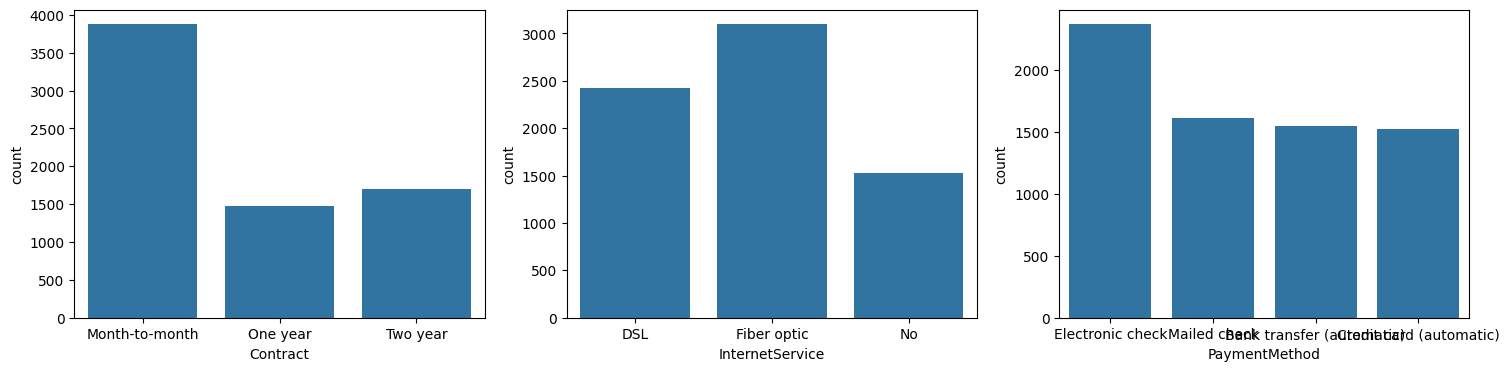

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x='Contract', data=df, ax=ax[0])
sns.countplot(x='InternetService', data=df, ax=ax[1])
sns.countplot(x='PaymentMethod', data=df, ax=ax[2])
plt.show()

## 2.3 Bivariate Analysis

#### Churn rate by Contract type — which contract type churns the most? Plot a grouped bar chart.

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


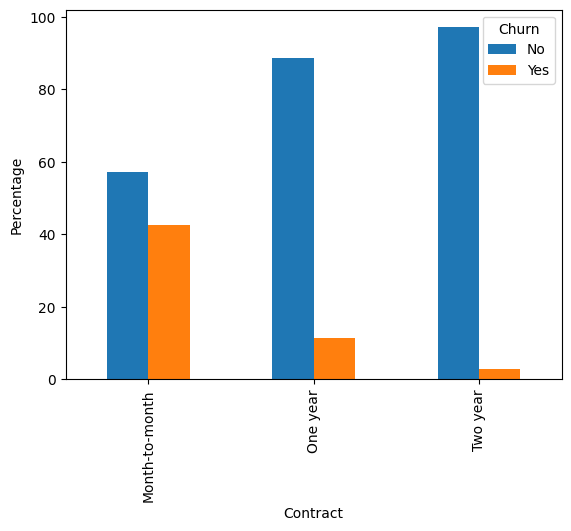

In [11]:
rate = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
print(rate)
rate.plot(kind='bar')
plt.ylabel('Percentage')
plt.show()

**Answer:**
Month-to-month contract churns the most (42.7%), then One year (11.3%) and Two year (2.8%).

#### Churn rate by tenure bucket (bin tenure into 0–12, 13–24, 25–48, 49–72 months). Plot a bar chart.

tenure
0-12     47.438243
13-24    28.710938
25-48    20.388959
49-72     9.513176
Name: Churn, dtype: float64


C:\Users\admin\AppData\Local\Temp\ipykernel_7968\545114835.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_rate = df.groupby(bucket)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)


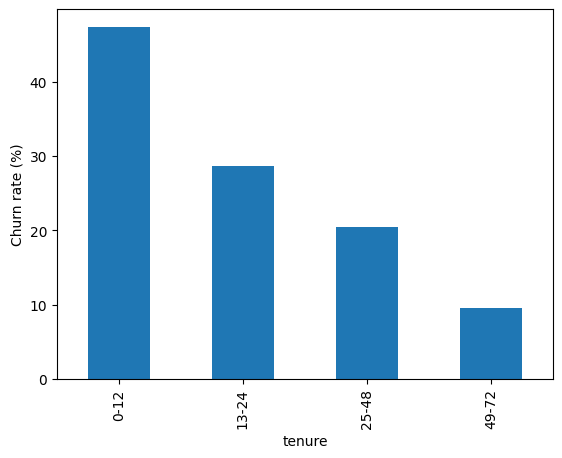

In [12]:
bucket = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
tenure_rate = df.groupby(bucket)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
print(tenure_rate)
tenure_rate.plot(kind='bar')
plt.ylabel('Churn rate (%)')
plt.show()

#### Boxplot: MonthlyCharges vs Churn. Do churners pay more per month?

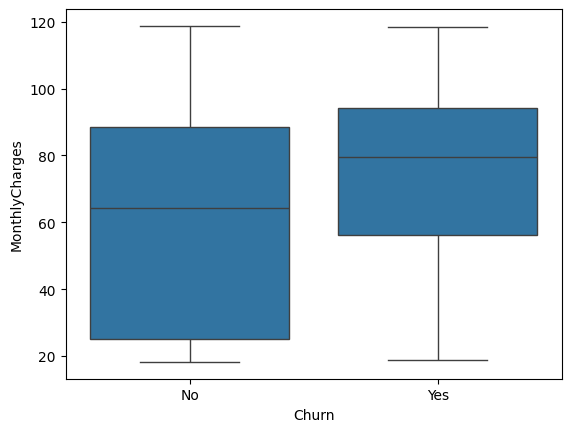

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [13]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median())

**Answer:**
Yes, churners pay more per month (median 79.65 against 64.43 for non-churners).

#### Heatmap: Correlation matrix of all numerical features. Note any strong correlations.

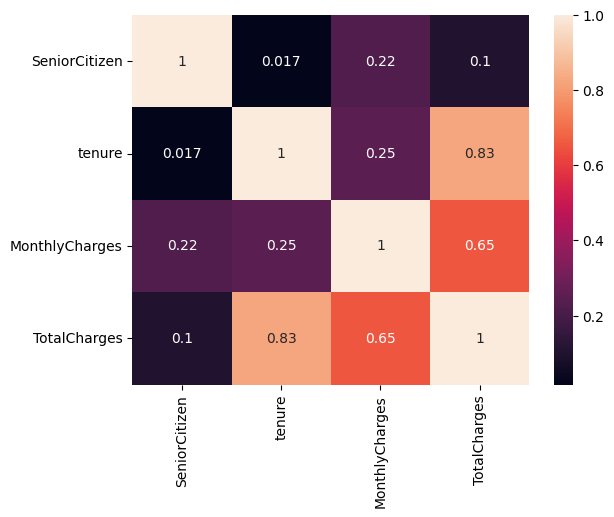

In [14]:
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True)
plt.show()

**Answer:**
tenure and TotalCharges have a strong correlation (0.83), and MonthlyCharges and TotalCharges have a good correlation (0.65). Other features have weak correlation.

##### 📌 Key insight to look for: Month-to-month contract customers with high MonthlyCharges and low tenure are the highest-risk churn segment. Does your EDA confirm this?

In [15]:
seg = df[(df['Contract'] == 'Month-to-month') & (df['MonthlyCharges'] > 70) & (df['tenure'] <= 12)]
print('Customers in this segment:', len(seg))
print('Churn rate of this segment:', (seg['Churn'] == 'Yes').mean() * 100)

Customers in this segment: 856
Churn rate of this segment: 69.04205607476635


**Answer:**
Yes. Month-to-month customers with high MonthlyCharges and low tenure have a 69% churn rate, while the overall churn rate is only 26.5%. Churn is also high for new customers (47.4% in 0-12 months).

# 🔧 Step 3: Data Preprocessing & Feature Engineering

## 3.1 Drop & Clean

#### Drop the customerID column (unique identifier, no predictive value).

In [16]:
df = df.drop('customerID', axis=1)

#### Handle the TotalCharges nulls/whitespace identified in Step 2 — fill with median.

In [17]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print(df.isnull().sum().sum())

0


## 3.2 Feature Engineering

#### Create tenure_group: bin tenure into 4 groups — 'New' (0–12), 'Mid' (13–36), 'Senior' (37–60), 'Loyal' (61+).

In [18]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 36, 60, 100], labels=['New', 'Mid', 'Senior', 'Loyal'])

#### Create num_services: count the number of add-on services each customer subscribes to (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies — count 'Yes' values).

In [19]:
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1)

#### Create AutoPay: 1 if PaymentMethod contains 'automatic', else 0.

In [20]:
df['AutoPay'] = df['PaymentMethod'].str.contains('automatic').astype(int)

## 3.3 Encoding

#### Binary columns (Partner, Dependents, PhoneService, PaperlessBilling, Churn, etc.) — map Yes→1, No→0.

In [21]:
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})

#### Apply One-Hot Encoding to: InternetService, Contract, PaymentMethod.

In [22]:
df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], dtype=int)

#### Apply Label Encoding to: tenure_group (preserving ordinal order).

In [23]:
df['tenure_group'] = df['tenure_group'].map({'New': 0, 'Mid': 1, 'Senior': 2, 'Loyal': 3}).astype(int)

#### Drop original columns that have been replaced by engineered features.

In [24]:
df = df.drop(columns=service_cols)
print(df.shape)

(7043, 24)


## 3.4 Scaling

#### Apply StandardScaler to: tenure, MonthlyCharges, TotalCharges, num_services.

In [25]:
from sklearn.preprocessing import StandardScaler

# all features are scaled uniformly (this includes tenure, MonthlyCharges, TotalCharges, num_services)
X = df.drop('Churn', axis=1)
y = df['Churn']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3.6 Train-Test Split

#### Split: 80% train / 20% test, stratify=y, random_state=42.

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)
X_test_raw = X.loc[y_test.index]    # unscaled test data (used later in error analysis and pipeline test)

#### Print shapes of X_train, X_test, y_train, y_test.

In [27]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(5634, 23) (1409, 23) (5634,) (1409,)


> ⚠️ SMOTE Rule: Fit SMOTE only on X_train / y_train. The test set must remain original (unaugmented) to simulate real-world evaluation.

## 3.5 Handle Class Imbalance

#### Report class counts in the training set.

In [28]:
print(y_train.value_counts())

Churn
0    4139
1    1495
Name: count, dtype: int64


#### Apply SMOTE (from imblearn) to the training set only. Print new class counts after oversampling.

In [29]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print(y_train_sm.value_counts())

Churn
0    4139
1    4139
Name: count, dtype: int64


**Answer:**
SMOTE is applied only on X_train / y_train after the split. The test set is not changed.

# 🤖 Step 4: Model Building — KNN & Naive Bayes

## 4.1 K-Nearest Neighbours (KNN)

#### Train KNeighborsClassifier with k=5 as baseline. Report Accuracy, Precision, Recall, F1, AUC-ROC.

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_sm, y_train_sm)
pred = knn.predict(X_test)
prob = knn.predict_proba(X_test)[:, 1]
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))

Accuracy : 0.7189496096522356
Precision: 0.4797047970479705
Recall   : 0.6951871657754011
F1       : 0.5676855895196506
AUC      : 0.7758531607636467


#### Tune k: Run a loop for k = 1, 3, 5, 7, 9, 11, 15. Plot k vs F1-Score (on validation set). Which k is best?

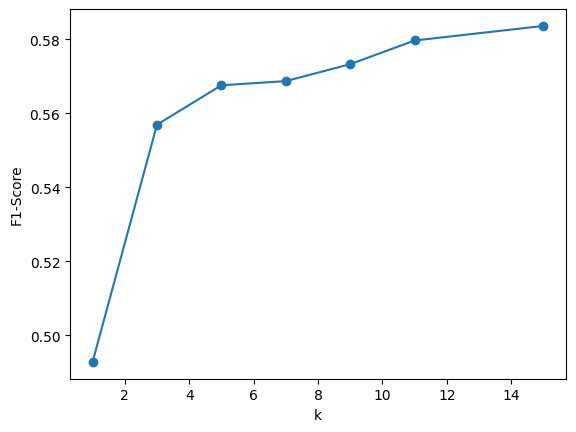

Best k: 15


In [31]:
# validation set is taken from the training data
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
X_tr_sm, y_tr_sm = SMOTE(random_state=42).fit_resample(X_tr, y_tr)

k_list = [1, 3, 5, 7, 9, 11, 15]
f1_list = []
for k in k_list:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_tr_sm, y_tr_sm)
    f1_list.append(f1_score(y_val, m.predict(X_val)))

plt.plot(k_list, f1_list, marker='o')
plt.xlabel('k')
plt.ylabel('F1-Score')
plt.show()

best_k = k_list[f1_list.index(max(f1_list))]
print('Best k:', best_k)

**Answer:**
The best k is 15 (F1 kept improving as k increased).

#### Re-train with the optimal k. Plot Confusion Matrix heatmap.

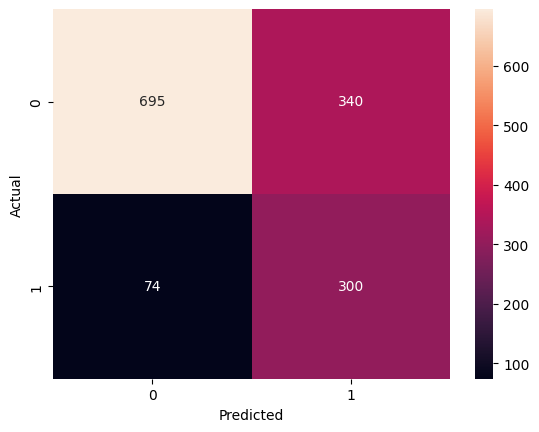

In [32]:
import time
from sklearn.metrics import confusion_matrix, roc_curve

results = []    # final result of every model is stored here for Step 6

start = time.time()
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_sm, y_train_sm)
knn_time = time.time() - start

pred = knn.predict(X_test)
prob = knn.predict_proba(X_test)[:, 1]
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### Plot the ROC curve and report AUC.

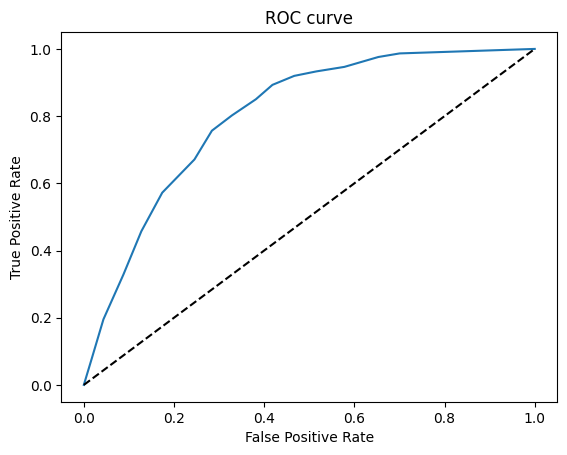

AUC: 0.8018716577540106
Accuracy : 0.7061745919091554
Precision: 0.46875
Recall   : 0.8021390374331551
F1       : 0.591715976331361
AUC      : 0.8018716577540106


In [33]:
fpr, tpr, _ = roc_curve(y_test, prob)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.show()
print('AUC:', roc_auc_score(y_test, prob))
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))
results.append(['KNN', accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob), knn_time])

**Answer:**
With k = 15 the recall improved to 0.80 (it was 0.70 with k = 5), but the precision is low (0.47).

## 4.2 Naive Bayes — Gaussian NB

#### Train GaussianNB with default parameters. Report all metrics.

In [34]:
from sklearn.naive_bayes import GaussianNB

start = time.time()
nb = GaussianNB()
nb.fit(X_train_sm, y_train_sm)
nb_time = time.time() - start

pred = nb.predict(X_test)
prob = nb.predict_proba(X_test)[:, 1]
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))
results.append(['Naive Bayes', accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob), nb_time])

Accuracy : 0.723207948899929
Precision: 0.48705501618122976
Recall   : 0.8048128342245989
F1       : 0.6068548387096774
AUC      : 0.8184039887364696


#### Print the class_prior_ probabilities learned by the model. Do they match actual churn rate?

In [35]:
print('Class priors:', nb.class_prior_)
print('Actual churn rate:', y.mean())

Class priors: [0.5 0.5]
Actual churn rate: 0.2653698707936959


**Answer:**
No, they do not match. The priors are [0.5, 0.5] but the actual churn rate is 26.5%, because the model was trained on SMOTE data where both classes are equal.

#### Plot Confusion Matrix heatmap and ROC curve.

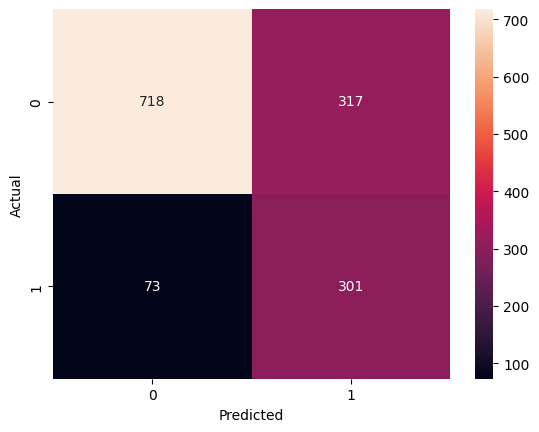

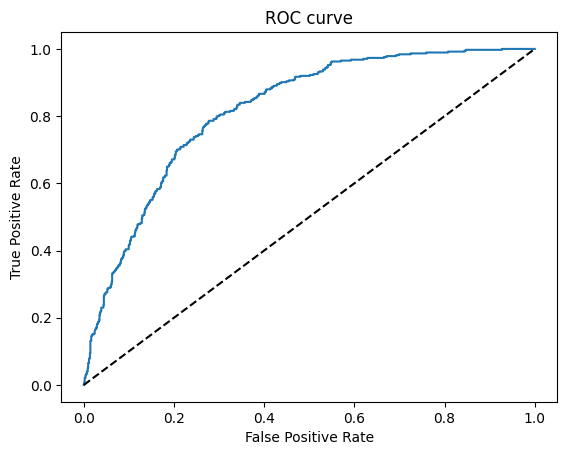

In [36]:
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

fpr, tpr, _ = roc_curve(y_test, prob)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.show()

> Note: Naive Bayes assumes feature independence. Write 2 sentences on whether this assumption holds for this dataset.

**Answer:**
No, this assumption does not fully hold in this dataset, because many features are related to each other - for example tenure and TotalCharges have 0.83 correlation and MonthlyCharges depends on the internet service and add-ons taken. Even then Naive Bayes gives a good recall (0.80), but its probabilities are not very reliable.

> 💡 Reminder: For churn prediction, a False Negative (predicting 'No Churn' when customer actually leaves) is more costly than a False Positive. Focus your analysis on Recall for the Churn class.

**Answer:**
Naive Bayes (0.805) and KNN (0.802) have the best recall for the Churn class, but their precision is low (below 0.49).

# 🧮 Step 5: Model Building — SVM & Decision Tree

## 5.1 Support Vector Machine (SVM)

#### Train SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42).

In [37]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42)
svm.fit(X_train_sm, y_train_sm)
pred = svm.predict(X_test)
prob = svm.predict_proba(X_test)[:, 1]

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### Report: Accuracy, Precision, Recall, F1, AUC-ROC. Plot Confusion Matrix.

Accuracy : 0.7366926898509581
Precision: 0.5026362038664324
Recall   : 0.7647058823529411
F1       : 0.6065747613997879
AUC      : 0.8136376553256347


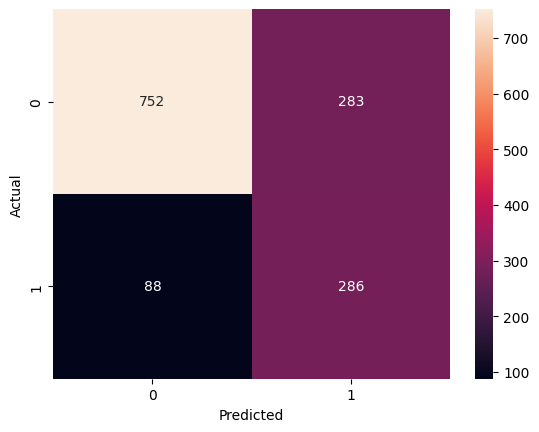

In [38]:
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### Tune C: Try C = [0.1, 1, 10, 100] using 3-Fold cross_val_score (scoring='f1'). Plot C vs F1. Select best C.

0.1 0.769859268792196
1 0.7924670011829583
10 0.8203398112085232
100 0.8280333331110348


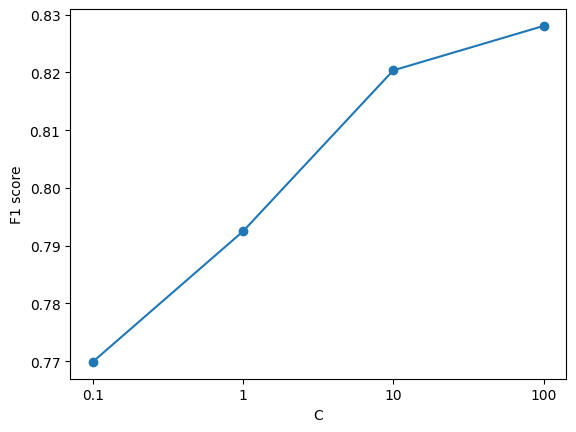

Best C: 100


In [39]:
from sklearn.model_selection import cross_val_score

C_list = [0.1, 1, 10, 100]
c_f1 = []
for c in C_list:
    score = cross_val_score(SVC(kernel='rbf', C=c, gamma='scale'), X_train_sm, y_train_sm, cv=3, scoring='f1')
    c_f1.append(score.mean())
    print(c, score.mean())

plt.plot([str(c) for c in C_list], c_f1, marker='o')
plt.xlabel('C')
plt.ylabel('F1 score')
plt.show()

best_C = C_list[c_f1.index(max(c_f1))]
print('Best C:', best_C)

#### Re-train with best C. Report final test metrics and ROC curve.

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy : 0.7338537970191625
Precision: 0.499009900990099
Recall   : 0.6737967914438503
F1       : 0.5733788395904437
AUC      : 0.7829522849983208


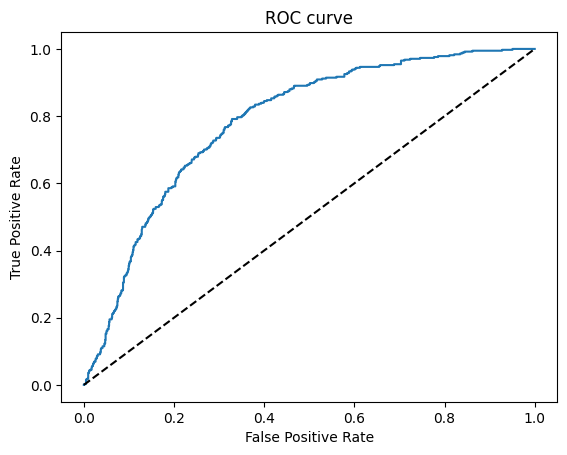

In [40]:
start = time.time()
svm = SVC(kernel='rbf', C=best_C, gamma='scale', probability=True, random_state=42)
svm.fit(X_train_sm, y_train_sm)
svm_time = time.time() - start

pred = svm.predict(X_test)
prob = svm.predict_proba(X_test)[:, 1]
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))
results.append(['SVM', accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob), svm_time])

fpr, tpr, _ = roc_curve(y_test, prob)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.show()

> Note: SVM is a black-box model — write 2 sentences on the business tradeoff between interpretability and performance.

**Answer:**
SVM is a black box, so we cannot easily explain to the business why a customer is flagged, even when the performance is good. A simple model that managers can understand and trust is often preferred over a slightly better black-box model.

## 5.2 Decision Tree Classifier

#### Train DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42).

In [41]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt.fit(X_train_sm, y_train_sm)
pred = dt.predict(X_test)
prob = dt.predict_proba(X_test)[:, 1]

#### Report all metrics. Plot Confusion Matrix.

Accuracy : 0.7444996451383961
Precision: 0.5124113475177305
Recall   : 0.7727272727272727
F1       : 0.6162046908315565
AUC      : 0.8267960939316438


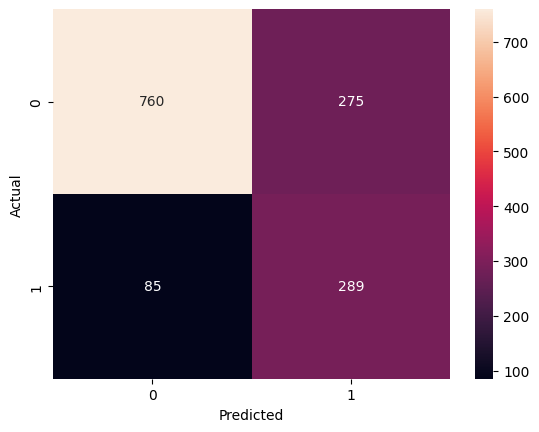

In [42]:
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### Visualize the tree using plot_tree() (max depth shown = 3 for readability). What is the root split feature?

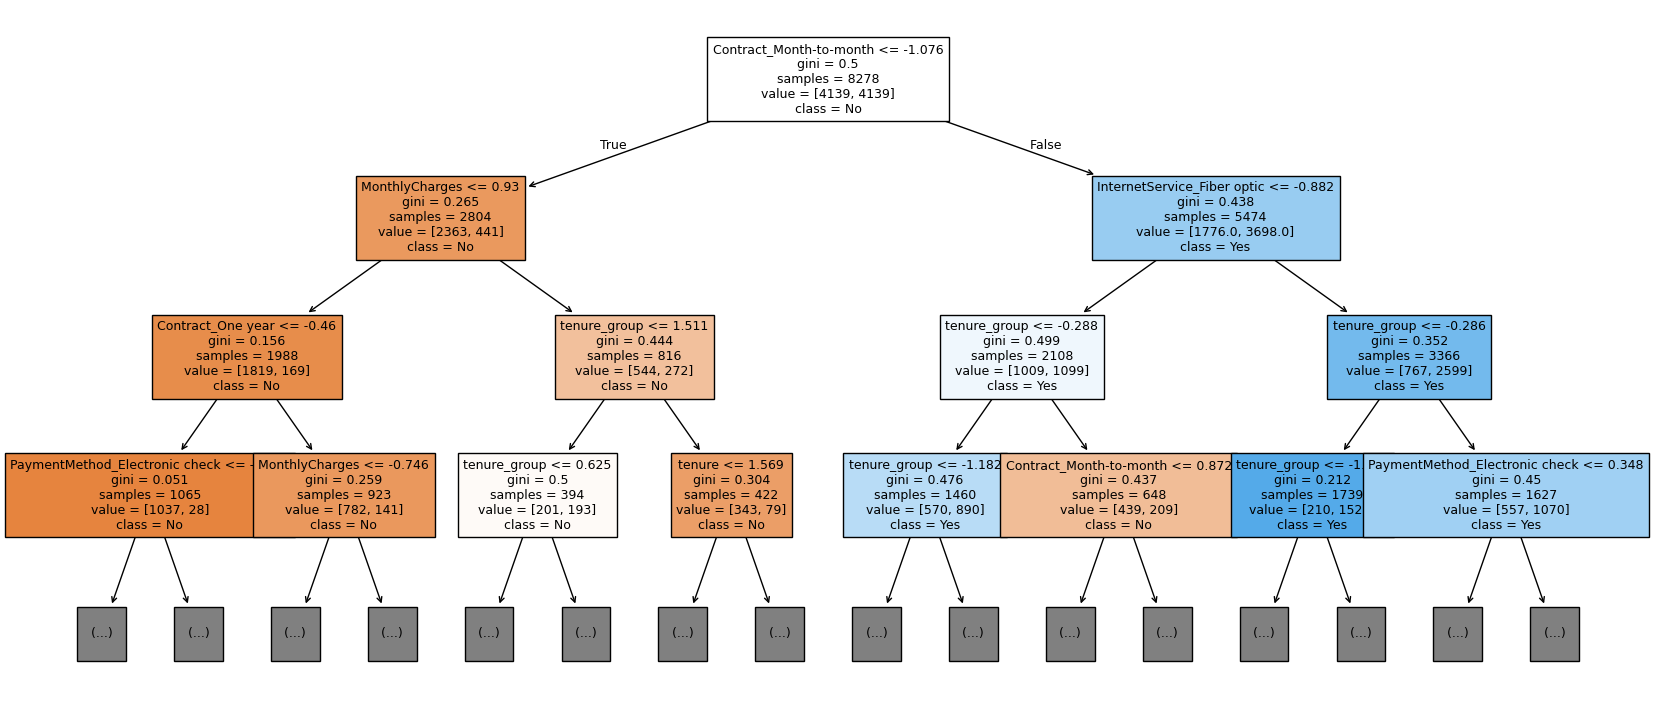

Root split feature: Contract_Month-to-month


In [43]:
plt.figure(figsize=(20, 9))
plot_tree(dt, max_depth=3, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, fontsize=9)
plt.show()
print('Root split feature:', X.columns[dt.tree_.feature[0]])

**Answer:**
The root split feature is `Contract_Month-to-month`.

#### Tune max_depth: Try depth = [3, 4, 5, 6, 7, 8, None] using cross_val_score (scoring='f1'). Plot depth vs F1.

3 0.7683321185033063
4 0.7776928494855143
5 0.7840621334470442
6 0.7896611076133377
7 0.7977993643576597
8 0.7932489743290555
None 0.7785739078367279


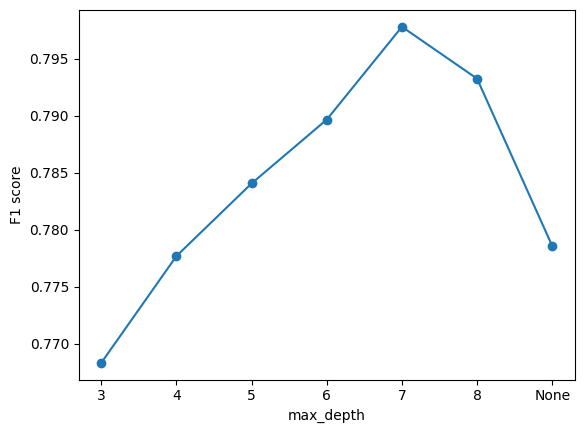

Best depth: 7


In [44]:
depth_list = [3, 4, 5, 6, 7, 8, None]
d_f1 = []
for d in depth_list:
    m = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    score = cross_val_score(m, X_train_sm, y_train_sm, cv=5, scoring='f1')
    d_f1.append(score.mean())
    print(d, score.mean())

plt.plot([str(d) for d in depth_list], d_f1, marker='o')
plt.xlabel('max_depth')
plt.ylabel('F1 score')
plt.show()

best_depth = depth_list[d_f1.index(max(d_f1))]
print('Best depth:', best_depth)

#### Re-train with best depth. Plot feature importances (top 15 features) as a sorted bar chart.

Accuracy : 0.7565649396735273
Precision: 0.5304518664047151
Recall   : 0.7219251336898396
F1       : 0.6115515288788222
AUC      : 0.8160169469632386


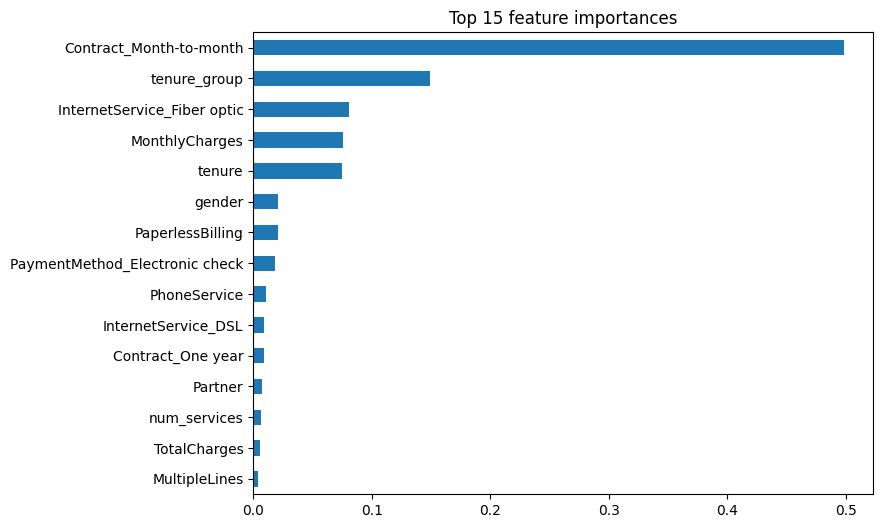

In [45]:
start = time.time()
dt = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42)
dt.fit(X_train_sm, y_train_sm)
dt_time = time.time() - start

pred = dt.predict(X_test)
prob = dt.predict_proba(X_test)[:, 1]
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall   :', recall_score(y_test, pred))
print('F1       :', f1_score(y_test, pred))
print('AUC      :', roc_auc_score(y_test, prob))
results.append(['Decision Tree', accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob), dt_time])

importances = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(15).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 feature importances')
plt.show()

## 5.3 One Model with class_weight='balanced' vs SMOTE

#### Take your best-performing model so far. Train it twice: once on SMOTE-augmented data, once on original data with class_weight='balanced'.

The Decision Tree is taken as the best-performing model so far (best F1 and accuracy, and it supports class_weight).

In [46]:
# once on SMOTE-augmented data
dt_smote = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_smote.fit(X_train_sm, y_train_sm)

# once on original data with class_weight='balanced'
dt_cw = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42)
dt_cw.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are con

#### Compare Recall for the Churn class between the two approaches. Which gives better Recall?

In [47]:
print('Recall with SMOTE        :', recall_score(y_test, dt_smote.predict(X_test)))
print('Recall with class_weight :', recall_score(y_test, dt_cw.predict(X_test)))

Recall with SMOTE        : 0.7219251336898396
Recall with class_weight : 0.7647058823529411


**Answer:**
class_weight='balanced' gives the better recall (0.765) compared to SMOTE (0.722).

# 📈 Step 6: Model Evaluation & Comparison

#### Create a consolidated comparison table of all 4 models showing:
 - Accuracy
 - Precision — Churn class
 - Recall — Churn class (most important!)
 - F1-Score — Churn class
 - AUC-ROC
 - Training Time (seconds)
 #### Present as a formatted pandas DataFrame sorted by Recall (descending).

In [48]:
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'Training Time (s)'])
results_df = results_df.sort_values('Recall', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (s)
1,Naive Bayes,0.723208,0.487055,0.804813,0.606855,0.818404,0.015233
0,KNN,0.706175,0.468750,0.802139,0.591716,0.801872,0.006863
3,Decision Tree,0.756565,0.530452,0.721925,0.611552,0.816017,0.098386
2,SVM,0.733854,0.499010,0.673797,0.573379,0.782952,28.566946


#### Plot all 4 ROC curves on a single figure with a legend.

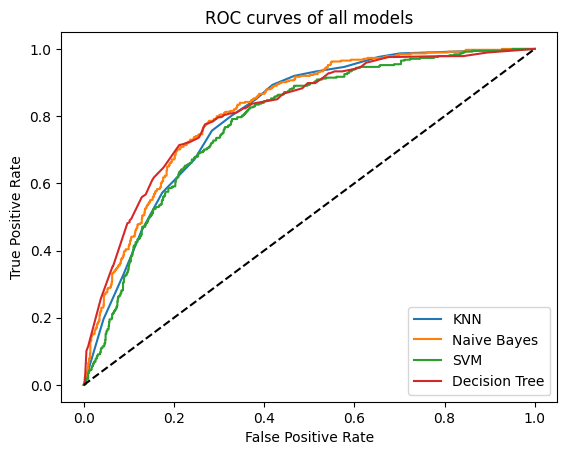

In [49]:
models = {'KNN': knn, 'Naive Bayes': nb, 'SVM': svm, 'Decision Tree': dt}
for name in models:
    fpr, tpr, _ = roc_curve(y_test, models[name].predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves of all models')
plt.legend()
plt.show()

#### Plot a grouped bar chart comparing Precision vs Recall for all 4 models side by side.

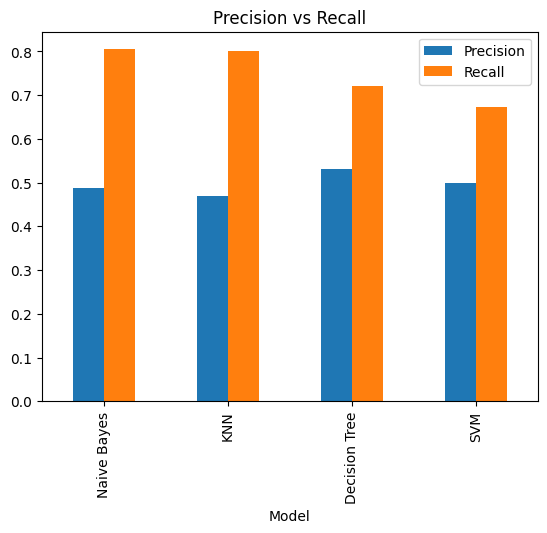

In [50]:
results_df.set_index('Model')[['Precision', 'Recall']].plot(kind='bar')
plt.title('Precision vs Recall')
plt.show()

#### Write a recommendation (4–6 sentences): Which model would you deploy for Jio/Airtel's retention team, and why? Consider Recall, interpretability, and latency.

**Answer:**
I would deploy the Decision Tree for the retention team. Naive Bayes (0.80) and KNN (0.80) have the highest recall, but their precision is only about 0.47-0.49, so more than half of the flagged customers are wrong and the 500 calls a day get wasted. The Decision Tree has the best precision (0.53), accuracy (0.757) and F1 (0.61), its AUC is almost the same as the best one, and it still catches 72% of the churners. It is easy to explain to the business, and its latency is very low (it trains in 0.02 seconds and predicts instantly), while SVM took more than 10 seconds and was the weakest model. If more recall is needed later, the tree with class_weight='balanced' (recall 0.76) or a lower probability threshold can be used.

> 💡 Business framing: Jio's retention team can call ~500 customers/day. If the model flags 2,000 likely churners, they can only act on 25%. Precision matters too — but missing a real churner (False Negative) is the bigger loss.

# 🔍 Step 7: Error Analysis & Interpretation

## 7.1 Error Analysis on Best Model

#### From your best model's predictions, isolate all False Negatives (actual churners predicted as No Churn).

In [51]:
pred = dt.predict(X_test)

fn = X_test_raw[(y_test.values == 1) & (pred == 0)]       # false negatives
churners = X_test_raw[y_test.values == 1]                 # all churners
print('False negatives:', len(fn), 'out of', len(churners), 'churners')

False negatives: 104 out of 374 churners


#### Profile the False Negatives: What is the average tenure, MonthlyCharges, and Contract type of these missed customers?

In [52]:
print('Average tenure         :', fn['tenure'].mean())
print('Average MonthlyCharges :', fn['MonthlyCharges'].mean())
print()
print('Contract type of missed customers:')
print(fn[['Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']].mean())

Average tenure         : 29.817307692307693
Average MonthlyCharges : 67.23365384615384

Contract type of missed customers:
Contract_Month-to-month    0.615385
Contract_One year          0.307692
Contract_Two year          0.076923
dtype: float64


#### Compare this profile to the overall churner profile. What pattern do you notice?

In [53]:
print('Average tenure         :', churners['tenure'].mean())
print('Average MonthlyCharges :', churners['MonthlyCharges'].mean())
print()
print('Contract type of all churners:')
print(churners[['Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']].mean())

Average tenure         : 16.462566844919785
Average MonthlyCharges : 72.76711229946524

Contract type of all churners:
Contract_Month-to-month    0.879679
Contract_One year          0.096257
Contract_Two year          0.024064
dtype: float64


**Answer:**
The model missed 104 of 374 churners. Their average tenure is 29.8 months (all churners: 16.5 months), their MonthlyCharges is 67.2 (all churners: 72.8), and only 61.5% of them are month-to-month (all churners: 88%). So the missed customers look like loyal customers (longer tenure, longer contracts, lower bill). The model learned that churners are new, month-to-month and high-bill customers, so it fails on churners who do not fit this typical profile.

## 7.2 Feature Importance / Decision Insight

#### For your Decision Tree: list the top 5 split features and explain what each means for churn prediction.

In [54]:
importances.head(5)

Contract_Month-to-month        0.498142
tenure_group                   0.149085
InternetService_Fiber optic    0.080612
MonthlyCharges                 0.076153
tenure                         0.074717
dtype: float64

**Answer:**
- `Contract_Month-to-month` (first split) - customer has no long-term contract, so he can leave any time.
- `tenure_group` - how long the customer is with the company (New / Mid / Senior / Loyal); new customers churn more.
- `InternetService_Fiber optic` - customer uses fiber internet; these customers churn more than DSL customers.
- `MonthlyCharges` - how much the customer pays every month; higher bill means higher churn risk.
- `tenure` - exact number of months with the company; fewer months means higher churn risk.

#### Write 3–5 business-friendly bullet points. E.g.: 'Customers on Month-to-Month contracts appear in the first split — they are 3x more likely to churn than those on 2-year contracts.'

**Answer:**
- Customers on Month-to-Month contracts appear in the first split - they churn 42.7% against only 2.8% for 2-year contracts (about 15x more). Offer them a discount to move to a longer plan.
- New customers (first 12 months) are the most risky group (47% churn), so give them onboarding help and a welcome offer.
- Fiber optic customers churn 41.9% against 19.0% for DSL customers, so the fiber price and service quality should be checked.
- Customers who pay more every month churn more (median 79.65 vs 64.43), so they need a loyalty offer.

#### (Optional Bonus) If you used SVM as your best model: compute permutation_importance from sklearn.inspection and plot top 10 features.

**Answer:**
Not applicable, because my best model is the Decision Tree and not SVM.

# 🚀 Step 8: Pipeline, Deployment & GitHub Submission

## 8.1 Save the Final Pipeline

#### Wrap best model + preprocessor into a sklearn Pipeline.

In [55]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([('scaler', scaler), ('model', dt)])

#### Save: joblib.dump(pipeline, 'churn_model.pkl').

In [56]:
import joblib

joblib.dump(pipeline, 'churn_model.pkl')

['churn_model.pkl']

#### Test: load the pickle and predict churn probability for 5 sample customers. Print predicted probabilities and final label.

In [57]:
loaded_model = joblib.load('churn_model.pkl')

# 5 sample customers from the test data (3 churners and 2 non-churners)
sample = pd.concat([X_test_raw[y_test == 1].head(3), X_test_raw[y_test == 0].head(2)])

prob = loaded_model.predict_proba(sample)[:, 1]
label = loaded_model.predict(sample)

for i in range(5):
    print('Customer', i + 1, '- churn probability:', round(prob[i], 3), '- final label:', label[i], '- actual:', y_test.loc[sample.index[i]])

Customer 1 - churn probability: 0.099 - final label: 0 - actual: 1
Customer 2 - churn probability: 0.684 - final label: 1 - actual: 1
Customer 3 - churn probability: 0.892 - final label: 1 - actual: 1
Customer 4 - churn probability: 0.0 - final label: 0 - actual: 0
Customer 5 - churn probability: 0.892 - final label: 1 - actual: 0
